In [2]:
!pip install -q tensorflow matplotlib seaborn scikit-learn

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json
import time

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

In [4]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1342s 8us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


In [5]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

print("Preprocessing completed!")

Preprocessing completed!


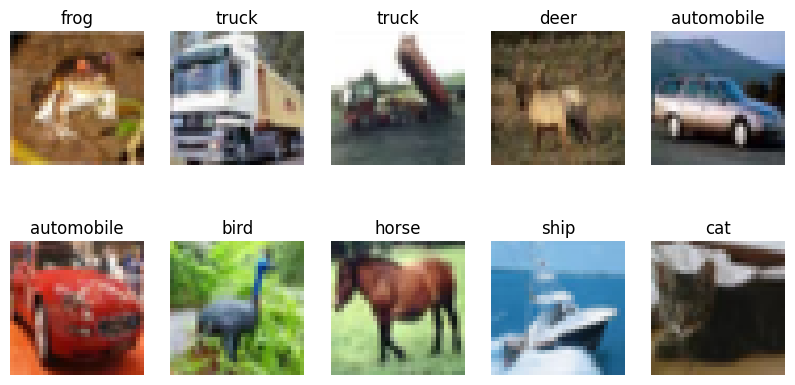

In [6]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.show()

In [7]:
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315,722 (1.20 MB)

 Trainable params: 315,722 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 59s 91ms/step - accuracy: 0.4004 - loss: 1.6385 - val_accuracy: 0.5338 - val_loss: 1.3378
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.5366 - loss: 1.2907 - val_accuracy: 0.5943 - val_loss: 1.1541
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.5904 - loss: 1.1567 - val_accuracy: 0.6256 - val_loss: 1.0621
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 80s 87ms/step - accuracy: 0.6249 - loss: 1.0665 - val_accuracy: 0.6504 - val_loss: 1.0056
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.6507 - loss: 0.9992 - val_accuracy: 0.6614 - val_loss: 0.9732


In [9]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max'
)

print("Checkpoint callback created.")

Checkpoint callback created.


In [10]:
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2,
    callbacks=[checkpoint]
)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.6696 - loss: 0.9421 - val_accuracy: 0.6777 - val_loss: 0.9236
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 87ms/step - accuracy: 0.6845 - loss: 0.8928 - val_accuracy: 0.6800 - val_loss: 0.9369
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 87ms/step - accuracy: 0.7021 - loss: 0.8446 - val_accuracy: 0.6885 - val_loss: 0.8987
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.7167 - loss: 0.8049 - val_accuracy: 0.6859 - val_loss: 0.9093
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 89ms/step - accuracy: 0.7293 - loss: 0.7682 - val_accuracy: 0.6967 - val_loss: 0.8928


In [11]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6947 - loss: 0.8970
Test Loss: 0.8969541788101196
Test Accuracy: 0.6947000026702881


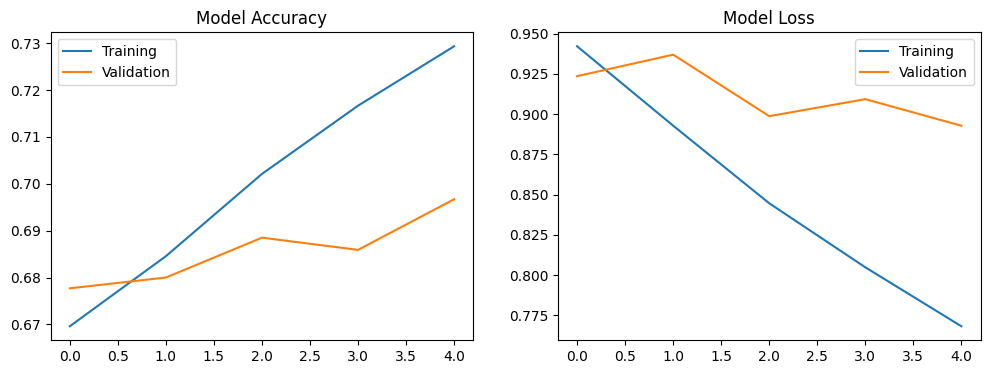

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Model Loss')
plt.legend()

plt.show()

In [13]:
predictions = model.predict(x_test[:5])

for i in range(5):
    predicted_class = np.argmax(predictions[i])

    print("Actual:", class_names[y_test[i]])
    print("Predicted:", class_names[predicted_class])
    print()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
Actual: cat
Predicted: cat

Actual: ship
Predicted: ship

Actual: ship
Predicted: ship

Actual: airplane
Predicted: airplane

Actual: frog
Predicted: deer



In [14]:
model.save('visionport_model.keras')

with open('class_names.json', 'w') as f:
    json.dump(class_names, f)

print("Model and class names saved successfully!")

Model and class names saved successfully!


In [15]:
predictions = model.predict(x_test)

y_pred = np.argmax(predictions, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step
              precision    recall  f1-score   support

    airplane       0.74      0.77      0.75      1000
  automobile       0.80      0.83      0.81      1000
        bird       0.70      0.43      0.53      1000
         cat       0.55      0.46      0.50      1000
        deer       0.54      0.73      0.62      1000
         dog       0.62      0.58      0.60      1000
        frog       0.79      0.76      0.77      1000
       horse       0.71      0.79      0.75      1000
        ship       0.73      0.85      0.79      1000
       truck       0.79      0.74      0.77      1000

    accuracy                           0.69     10000
   macro avg       0.70      0.69      0.69     10000
weighted avg       0.70      0.69      0.69     10000



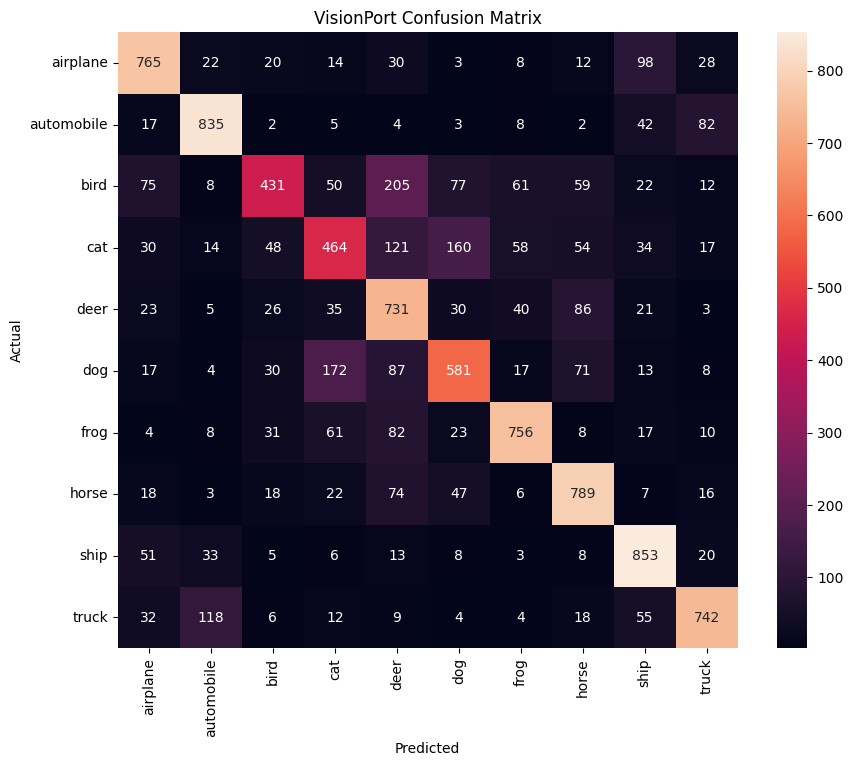

In [16]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("VisionPort Confusion Matrix")
plt.show()